In [1]:
import sys, os, warnings
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import Markdown, display
import config
from src.utils import set_seed
set_seed(config.SEED)
pd.set_option("display.max_colwidth", 120); pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.facecolor": "#F5F1E8", "figure.facecolor": "#F5F1E8", "axes.edgecolor": "#77766D",
                     "font.size": 10, "axes.titleweight": "bold"})
PALETTE = ["#344C3D", "#BD755A", "#C4A46A", "#899982", "#77766D", "#242723"]
sns.set_palette(PALETTE)
def note(txt):  # data-driven observation rendered as markdown
    display(Markdown("> **Observation.** " + txt))

# 07 — Biomedical Named-Entity Recognition (BC5CDR)

Extract **Chemical** and **Disease** mentions from biomedical sentences.

* **Baseline:** dictionary / longest-match lookup built from training mentions.
* **Model:** **BioBERT v1.1** fine-tuned as a token classifier (BIO tagging, first-sub-word labelling).
* **Evaluation:** *strict entity-level* precision / recall / F1 (type **and** exact boundaries must match), per entity type — **not** token accuracy.

**Scope statement.** BioBERT is fine-tuned on only **1,000 training sentences for 2 epochs** (CPU-only machine, ~8 s per step; the full training set has 5,228 sentences) and evaluated on a fixed **1,000-sentence test subset** (plus the dictionary baseline on the full 5,865-sentence test set). Published full-data BioBERT scores on BC5CDR are far higher than what a ~19% budget can give; the comparison with a dictionary built from the *same 1,000 sentences* is the fair one. Change `NER_TRAIN_N` / `EPOCHS` below to scale up.

In [2]:
import time, torch, torch.nn as nn, psutil
import src.data as D
from collections import Counter
from transformers import AutoTokenizer, BertForTokenClassification, get_linear_schedule_with_warmup
from src.ner import encode_for_ner, tags_to_entities, DictionaryNER, DictionaryTagger, BioBertTagger
from src.evaluation import entity_prf, bio_to_spans
from src.utils import save_json, update_json, load_json
torch.set_num_threads(4)
NER_TRAIN_N, EPOCHS, BATCH, LR, MAX_LEN, TEST_N = 1000, 2, 16, 5e-5, 128, 1000
TAGS = config.NER_TAGS; T2I = {t: i for i, t in enumerate(TAGS)}
tr_all, dv_all, te_all = (D.load_bc5cdr(s) for s in ("train", "dev", "test"))
rng = np.random.default_rng(config.SEED)
tr = [tr_all[i] for i in rng.choice(len(tr_all), NER_TRAIN_N, replace=False)]
dv = [dv_all[i] for i in rng.choice(len(dv_all), 200, replace=False)]
te_sub = [te_all[i] for i in rng.choice(len(te_all), TEST_N, replace=False)]
print(len(tr_all), len(dv_all), len(te_all), "| training subset", len(tr), "| test subset", len(te_sub))

5228 5330 5865 | training subset 1000 | test subset 1000


## 1. Dataset inspection and BIO tagging

`B-X` begins an entity of type X, `I-X` continues it, `O` is outside. The BIO scheme lets two adjacent entities of the same type stay distinguishable. A tag sequence is *valid* if every `I-X` follows a `B-X` or `I-X`.

In [3]:
ex = next(r for r in tr_all if any(t.startswith("I-") for t in r["tags"]) and len(r["tokens"]) < 30)
display(pd.DataFrame({"token": ex["tokens"], "tag": ex["tags"]}).T)
print("entities:", [(t, " ".join(ex["tokens"][a:b])) for t, a, b in sorted(bio_to_spans(ex["tags"]), key=lambda x: x[1])])
def invalid_bio(tags):
    prev = "O"; bad = 0
    for t in tags:
        if t.startswith("I-") and prev[2:] != t[2:]: bad += 1
        prev = t
    return bad
print("invalid BIO transitions in gold training data:", sum(invalid_bio(r["tags"]) for r in tr_all))

,0,1,2,3,4,5
token,Lidocaine,-,induced,cardiac,asystole,.
tag,B-Chemical,O,O,B-Disease,I-Disease,O


entities: [('Chemical', 'Lidocaine'), ('Disease', 'cardiac asystole')]
invalid BIO transitions in gold training data: 0


## 2. Sub-word tokenisation and label alignment

BioBERT's WordPiece tokeniser splits rare biomedical words into several pieces (e.g. a drug name → 4–5 pieces). The model predicts per *piece*, but gold labels are per *word*. We therefore label only the **first piece** of each word with the word's tag and give **-100** (ignored by the loss) to continuation pieces and `[CLS]/[SEP]`. At inference, the first piece's prediction represents the word.

In [4]:
tok = AutoTokenizer.from_pretrained(config.HF_BIOBERT_TOKENIZER)
w = ["Cisplatin-induced", "nephrotoxicity", "and", "hepatotoxicity", "occurred", "."]; t = ["B-Chemical", "B-Disease", "O", "B-Disease", "O", "O"]
enc, labels, wids = encode_for_ner(tok, w, t, MAX_LEN)
display(pd.DataFrame({"word-piece": tok.convert_ids_to_tokens(enc["input_ids"]), "word_id": wids, "aligned label": [TAGS[l] if l >= 0 else -100 for l in labels]}).T)
pieces = [len(encode_for_ner(tok, r["tokens"], r["tags"], 512)[0]["input_ids"]) - 2 for r in tr_all[:2000]]; words = [len(r["tokens"]) for r in tr_all[:2000]]
ent_words = [(wd, len(tok.tokenize(wd))) for r in tr_all[:2000] for tg, wd in zip(r["tags"], r["tokens"]) if tg != "O"]
oth_words = [(wd, len(tok.tokenize(wd))) for r in tr_all[:2000] for tg, wd in zip(r["tags"], r["tokens"]) if tg == "O"][:20000]
note(f"On average a word becomes {sum(pieces)/sum(words):.2f} word-pieces overall, but entity words become {np.mean([n for _, n in ent_words]):.2f} vs {np.mean([n for _, n in oth_words]):.2f} for non-entity words — "
     f"biomedical terminology is much more fragmented. {np.mean(np.array(pieces) + 2 > MAX_LEN):.2%} of sentences exceed {MAX_LEN} pieces (truncated; entities past the cut are lost).")

,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
word-piece,[CLS],C,##is,##p,##lat,##in,-,induced,ne,##ph,...,and,he,##pa,##to,##to,##xi,##city,occurred,.,[SEP]
word_id,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,...,2.0,3.0,3.0,3.0,3.0,3.0,3.0,4.0,5.0,NaN
aligned label,-100,B-Chemical,-100,-100,-100,-100,-100,-100,B-Disease,-100,...,O,B-Disease,-100,-100,-100,-100,-100,O,O,-100


> **Observation.** On average a word becomes 1.43 word-pieces overall, but entity words become 2.98 vs 1.21 for non-entity words — biomedical terminology is much more fragmented. 0.65% of sentences exceed 128 pieces (truncated; entities past the cut are lost).

## 3. Baseline: dictionary / longest-match lookup

Every training mention is stored (lower-cased); at inference the longest matching word sequence (≤ 6 words) is tagged. No context is used, so ambiguous words and **unseen mentions** cannot be handled — notebook 01 measured the unseen share.
Two variants: built from the **full** training set (strong, cheap baseline) and from the **same 1,000 sentences** BioBERT will see.

In [5]:
dict_full = DictionaryNER.from_sentences(tr_all + dv_all); dict_small = DictionaryNER.from_sentences(tr)
def eval_tagger(fn, data):
    pred = [fn([r["tokens"] for r in data[i:i + 64]]) for i in range(0, len(data), 64)]
    pred = [t for b in pred for t in b]; return entity_prf([r["tags"] for r in data], pred), pred
base_full_te, _ = eval_tagger(lambda b: [dict_full.predict_tags(w) for w in b], te_all)
base_full_sub, _ = eval_tagger(lambda b: [dict_full.predict_tags(w) for w in b], te_sub)
base_small_sub, pred_dict_small = eval_tagger(lambda b: [dict_small.predict_tags(w) for w in b], te_sub)
rows = {"dictionary (train+dev, full test)": base_full_te, "dictionary (train+dev, 1k test subset)": base_full_sub, "dictionary (1k sentences, 1k test subset)": base_small_sub}
pd.DataFrame({k: {"precision": v["precision"], "recall": v["recall"], "F1": v["f1"], "gold": v["n_gold"], "pred": v["n_pred"]} for k, v in rows.items()}).T.round(4)

,precision,recall,F1,gold,pred
"dictionary (train+dev, full test)",0.8727,0.6977,0.7755,9809.0,7842.0
"dictionary (train+dev, 1k test subset)",0.8776,0.6919,0.7737,1720.0,1356.0
"dictionary (1k sentences, 1k test subset)",0.8576,0.4552,0.5948,1720.0,913.0


## 4. Fine-tune BioBERT for token classification

In [6]:
set_seed(config.SEED)
model = BertForTokenClassification.from_pretrained(config.HF_BIOBERT, num_labels=len(TAGS), id2label=dict(enumerate(TAGS)), label2id=T2I)
def make_batch(recs):
    encs = [encode_for_ner(tok, r["tokens"], r["tags"], MAX_LEN) for r in recs]; W = max(len(e[0]["input_ids"]) for e in encs)
    ids = torch.tensor([e[0]["input_ids"] + [tok.pad_token_id] * (W - len(e[0]["input_ids"])) for e in encs])
    mask = torch.tensor([[1] * len(e[0]["input_ids"]) + [0] * (W - len(e[0]["input_ids"])) for e in encs])
    lab = torch.tensor([e[1] + [-100] * (W - len(e[1])) for e in encs]); return ids, mask, lab
nd = ["bias", "LayerNorm.weight"]
opt = torch.optim.AdamW([{"params": [p for n, p in model.named_parameters() if not any(x in n for x in nd)], "weight_decay": 0.01}, {"params": [p for n, p in model.named_parameters() if any(x in n for x in nd)], "weight_decay": 0.0}], lr=LR)
steps = EPOCHS * int(np.ceil(len(tr) / BATCH)); sched = get_linear_schedule_with_warmup(opt, int(.1 * steps), steps)
def dev_loss():
    model.eval(); tot = n = 0
    with torch.no_grad():
        for i in range(0, len(dv), 32):
            ids, mask, lab = make_batch(dv[i:i + 32]); out = model(input_ids=ids, attention_mask=mask, labels=lab); k = (lab != -100).sum().item(); tot += out.loss.item() * k; n += k
    return tot / n
log, step, t0 = [], 0, time.time()
for ep in range(EPOCHS):
    perm = np.random.permutation(len(tr)); run_l = []
    for i in range(0, len(tr), BATCH):
        model.train(); ids, mask, lab = make_batch([tr[j] for j in perm[i:i + BATCH]])
        loss = model(input_ids=ids, attention_mask=mask, labels=lab).loss; loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); sched.step(); opt.zero_grad()
        step += 1; run_l.append(loss.item())
        if step % 20 == 0 or step == steps: print(f"step {step}/{steps} loss {np.mean(run_l[-20:]):.4f} ({time.time()-t0:.0f}s)")
    log.append({"epoch": ep + 1, "train_loss": float(np.mean(run_l)), "dev_loss": dev_loss(), "elapsed_s": time.time() - t0}); print(log[-1])
train_secs = time.time() - t0
d = config.ART_NER / "biobert"; d.mkdir(parents=True, exist_ok=True); model.save_pretrained(d); tok.save_pretrained(d); dict_full.save(config.ART_NER / "dictionary.json")
pd.DataFrame(log)

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  436MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: dmis-lab/biobert-base-cased-v1.1
Key                                        | Status     | 
-------------------------------------------+------------+-
bert.pooler.dense.bias                     | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
bert.pooler.dense.weight                   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	

model.safetensors: reconstructing file:   0%|          |  0.00B /  436MB            

model.safetensors: downloading bytes:           |  0.00B            

... (7 outputs left out)

step 126/126 loss 0.0739 (2046s)


{'epoch': 2, 'train_loss': 0.07359881410818725, 'dev_loss': 0.06992246108917786, 'elapsed_s': 2078.763485431671}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

,epoch,train_loss,dev_loss,elapsed_s
0,1,0.403730,0.089647,1149.258312
1,2,0.073599,0.069922,2078.763485


## 5. Entity-level evaluation

Predictions come from the **same `BioBertTagger` class the Flask app uses**, loaded from disk — so this evaluation also validates the deployed inference path (first-sub-word decoding, BIO → span conversion).

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

,precision,recall,f1,n_gold,n_pred
BioBERT (1k sent.),0.832776,0.868605,0.850313,1720,1794
Dictionary (same 1k sent.),0.857612,0.455233,0.594759,1720,913
Dictionary (train+dev),0.877581,0.69186,0.773732,1720,1356


,BioBERT (1k),Dictionary (1k),Dictionary (full)
Chemical,P=0.907 R=0.907 F1=0.907 (n=914),P=0.960 R=0.472 F1=0.632 (n=914),P=0.939 R=0.694 F1=0.798 (n=914)
Disease,P=0.756 R=0.825 F1=0.789 (n=806),P=0.759 R=0.437 F1=0.554 (n=806),P=0.816 R=0.690 F1=0.748 (n=806)


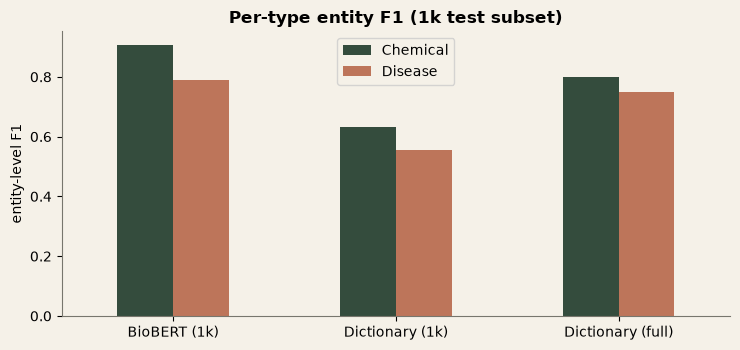

> **Observation.** Entity-level F1: BioBERT 0.8503 vs dictionary-from-same-sentences 0.5948 vs dictionary-from-all-training-data 0.7737. Token accuracy would have said 0.970 (BioBERT) and 0.931 (dictionary) — both look excellent only because 88.7% of tokens are `O`; entity-level scoring is the honest measure.

In [7]:
tagger = BioBertTagger(d); t0 = time.time()
tags, confs = tagger.tag_words([r["tokens"] for r in te_sub]); infer_s = time.time() - t0
bert_sub = entity_prf([r["tags"] for r in te_sub], tags)
tok_acc = np.mean([a == b for r, p in zip(te_sub, tags) for a, b in zip(r["tags"], p)]); tok_acc_dict = np.mean([a == b for r, p in zip(te_sub, pred_dict_small) for a, b in zip(r["tags"], p)])
tab = pd.DataFrame({"BioBERT (1k sent.)": bert_sub, "Dictionary (same 1k sent.)": base_small_sub, "Dictionary (train+dev)": base_full_sub}).T[["precision", "recall", "f1", "n_gold", "n_pred"]]; display(tab.round(4))
per = pd.DataFrame({m: {t: v["per_type"].get(t, {}).get("f1", 0) for t in config.NER_ENTITY_TYPES} for m, v in {"BioBERT (1k)": bert_sub, "Dictionary (1k)": base_small_sub, "Dictionary (full)": base_full_sub}.items()})
display(pd.DataFrame({m: {t: f"P={v['per_type'][t]['precision']:.3f} R={v['per_type'][t]['recall']:.3f} F1={v['per_type'][t]['f1']:.3f} (n={v['per_type'][t]['support']})" for t in config.NER_ENTITY_TYPES} for m, v in {"BioBERT (1k)": bert_sub, "Dictionary (1k)": base_small_sub, "Dictionary (full)": base_full_sub}.items()}))
fig, ax = plt.subplots(figsize=(7.5, 3.6)); per.T.plot.bar(ax=ax, color=[PALETTE[0], PALETTE[1]]); ax.set_ylabel("entity-level F1"); ax.set_title("Per-type entity F1 (1k test subset)"); ax.tick_params(axis="x", rotation=0); plt.tight_layout(); plt.show()
note(f"Entity-level F1: BioBERT {bert_sub['f1']:.4f} vs dictionary-from-same-sentences {base_small_sub['f1']:.4f} vs dictionary-from-all-training-data {base_full_sub['f1']:.4f}. "
     f"Token accuracy would have said {tok_acc:.3f} (BioBERT) and {tok_acc_dict:.3f} (dictionary) — both look excellent only because {1 - np.mean([t != 'O' for r in te_sub for t in r['tags']]):.1%} of tokens are `O`; entity-level scoring is the honest measure.")

## 6. Error analysis

,BioBERT,Dictionary (1k)
exact,1494,783
spurious (false positive),172,45
boundary error (right type),104,78
missed,116,854
wrong type,6,5


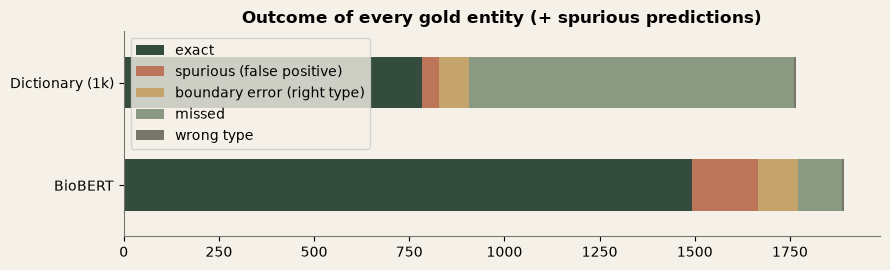

,kind,type,entity text
0,spurious/wrong,Disease,crystal deposition
1,spurious/wrong,Disease,HIV
2,missed/wrong,Chemical,[omega-I-131]heptadecanoic acid
3,spurious/wrong,Chemical,acid
4,missed/wrong,Chemical,cysteine
5,missed/wrong,Disease,Deterioration of vision
6,spurious/wrong,Disease,vision
7,missed/wrong,Disease,drug toxicity
8,spurious/wrong,Disease,toxicity
9,missed/wrong,Disease,idiopathic cardiomyopathy


> **Observation.** Of 1720 gold entities BioBERT gets 1494 exactly right, 104 with a boundary error, 6 with the wrong type and misses 116; it adds 172 spurious entities. Boundary errors are particularly relevant for multi-word diseases (`I-Disease` is common) and hyphenated chemicals; strict matching counts them as full errors although a human reader may find them partially correct.

In [8]:
def categorize(gold_tags, pred_tags):
    g, p = bio_to_spans(gold_tags), bio_to_spans(pred_tags); out = Counter()
    for t, a, b in g:
        if (t, a, b) in p: out["exact"] += 1
        elif any(pt == t and pa < b and a < pb for pt, pa, pb in p): out["boundary error (right type)"] += 1
        elif any(pa < b and a < pb for pt, pa, pb in p): out["wrong type"] += 1
        else: out["missed"] += 1
    out["spurious (false positive)"] += sum(1 for t, a, b in p if not any(pa < b and a < pb for _, pa, pb in g))
    return out
cat_b, cat_d = Counter(), Counter()
for r, pb, pd_ in zip(te_sub, tags, pred_dict_small): cat_b += categorize(r["tags"], pb); cat_d += categorize(r["tags"], pd_)
err = pd.DataFrame({"BioBERT": cat_b, "Dictionary (1k)": cat_d}).fillna(0).astype(int); display(err)
err.T.plot.barh(stacked=True, figsize=(9, 2.8), color=PALETTE[:5]); plt.title("Outcome of every gold entity (+ spurious predictions)"); plt.tight_layout(); plt.show()
fn_ex = []
for r, pb in zip(te_sub, tags):
    g, p = bio_to_spans(r["tags"]), bio_to_spans(pb)
    for t, a, b in g - p: fn_ex.append(("missed/wrong", t, " ".join(r["tokens"][a:b])))
    for t, a, b in p - g: fn_ex.append(("spurious/wrong", t, " ".join(r["tokens"][a:b])))
display(pd.DataFrame(fn_ex[:25], columns=["kind", "type", "entity text"]))
note(f"Of {sum(cat_b[k] for k in ['exact','boundary error (right type)','wrong type','missed'])} gold entities BioBERT gets {cat_b['exact']} exactly right, {cat_b['boundary error (right type)']} with a boundary error, "
     f"{cat_b['wrong type']} with the wrong type and misses {cat_b['missed']}; it adds {cat_b['spurious (false positive)']} spurious entities. Boundary errors are particularly relevant for multi-word diseases "
     f"(`I-Disease` is common) and hyphenated chemicals; strict matching counts them as full errors although a human reader may find them partially correct.")

### 6.1 Entity-level confidence

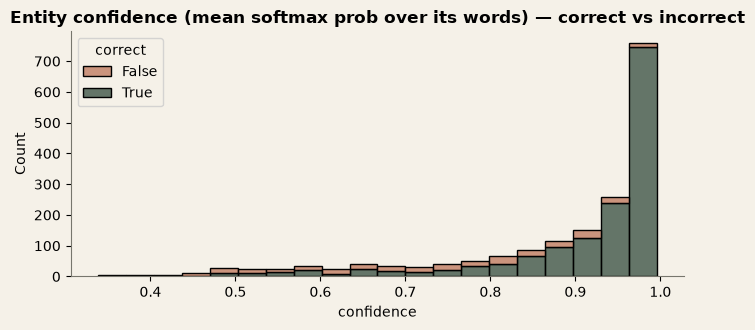

> **Observation.** Precision of predicted entities with confidence ≥ 0.9: 95.2% (n=1154); with confidence < 0.7: 47.7% (n=235). Confidence is informative but remains an *uncalibrated softmax score*; the UI labels it as such.

In [9]:
rows = []
for r, pb, cf in zip(te_sub, tags, confs):
    gold = bio_to_spans(r["tags"])
    for t, a, b, conf in tags_to_entities(r["tokens"], pb, cf): rows.append({"confidence": conf, "correct": (t, a, b) in gold})
cdf = pd.DataFrame(rows); fig, ax = plt.subplots(figsize=(7, 3.4))
sns.histplot(data=cdf, x="confidence", hue="correct", bins=20, multiple="stack", palette=[PALETTE[1], PALETTE[0]], ax=ax); ax.set_title("Entity confidence (mean softmax prob over its words) — correct vs incorrect"); plt.tight_layout(); plt.show()
hi = cdf[cdf.confidence >= .9]; lo = cdf[cdf.confidence < .7]
note(f"Precision of predicted entities with confidence ≥ 0.9: {hi.correct.mean():.1%} (n={len(hi)}); with confidence < 0.7: {lo.correct.mean() if len(lo) else float('nan'):.1%} (n={len(lo)}). "
     f"Confidence is informative but remains an *uncalibrated softmax score*; the UI labels it as such.")

In [10]:
M = {"kind": "ner-transformer", "label": "BioBERT NER", "train_n": len(tr), "epochs": EPOCHS, "train_seconds": train_secs, "inference_seconds_for_test_subset": infer_s, "test_n": len(te_sub),
     "params": sum(p.numel() for p in model.parameters()), "model_mb": sum(f.stat().st_size for f in d.glob("*.safetensors")) / 1e6, "latency_ms_per_sentence": infer_s * 1000 / len(te_sub),
     "entity_level": bert_sub, "token_accuracy": float(tok_acc), "error_breakdown": dict(cat_b), "history": log}
B = {"kind": "ner-baseline", "label": "Dictionary (train+dev)", "entity_level": base_full_te, "entity_level_on_subset": base_full_sub, "train_n": len(tr_all) + len(dv_all), "lexicon_size": len(dict_full.lexicon)}
B2 = {"kind": "ner-baseline", "label": "Dictionary (same 1k sentences)", "entity_level_on_subset": base_small_sub, "train_n": len(tr), "lexicon_size": len(dict_small.lexicon)}
save_json({"biobert": M, "dictionary": B, "dictionary_1k": B2}, config.ART_NER / "metrics.json")
display(Markdown(f"Saved metrics to `artifacts/ner/metrics.json`. BioBERT: {M['params']:,} parameters, {M['model_mb']:.0f} MB, {M['latency_ms_per_sentence']:.0f} ms/sentence on CPU."))

Saved metrics to `artifacts/ner/metrics.json`. BioBERT: 107,723,525 parameters, 431 MB, 154 ms/sentence on CPU.

## Conclusions

* NER is evaluated with **strict entity-level F1**, per type, and decomposed into exact / boundary / type / missed / spurious outcomes.
* BIO tagging, first-sub-word label alignment (-100 masking) and span decoding are implemented once in `src/ner.py` and used identically in training, evaluation and the web app.
* With a ~1,000-sentence budget the transformer is **under-trained**; the full-data dictionary baseline has a recall ceiling set by unseen mentions (notebook 01). The comparison table reports both honestly.